# 02 - Busca semântica: recall@1, recall@3 e limiar de 'não consta'
**Requisito 03.** Embeddings multilíngues (`intfloat/multilingual-e5-small`). O limiar é o score de similaridade abaixo do qual a resposta é 'não consta'.

In [1]:
# Setup (Colab: Ambiente de execução > Alterar tipo > GPU T4). Local: só rode a partir da raiz do repositório.
import os, sys, subprocess
REPO = "https://github.com/melo-zz/calcada-livre-genai.git"   # <- troque pelo link do repositório público da equipe
if os.path.exists("/content"):                                  # estamos no Colab
    if not os.path.exists("/content/repo"):
        subprocess.run(["git", "clone", REPO, "/content/repo"], check=True)
    os.chdir("/content/repo")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("pasta de trabalho:", os.getcwd())

pasta de trabalho: /content/repo


In [2]:
%pip install -q -r requirements.txt

In [3]:
import random, numpy as np
SEED = 42
random.seed(SEED); np.random.seed(SEED)
try:
    import torch; torch.manual_seed(SEED)
except ImportError:
    pass

In [4]:
import json, os
from src.kb import carregar_trechos
from avaliacao.casos import carregar
from src.retrieval import Retriever, recall_at_k, escolher_limiar
os.makedirs(".cache", exist_ok=True)
trechos = carregar_trechos("base/trechos.jsonl")
casos = carregar()
r = Retriever(trechos, cache=".cache/emb.npy")
print(len(trechos), "trechos indexados")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/40 [00:00<?, ?it/s]

1258 trechos indexados


In [5]:
rec, detalhes = recall_at_k(casos, r)
print(rec)
json.dump(rec, open("avaliacao/recall.json", "w"), indent=2)
import pandas as pd
df = pd.DataFrame(detalhes)
display(df[["pergunta", "top1", "score_top1", "ok@1", "ok@3"]].head(15))
df.to_csv("avaliacao/recall_detalhes.csv", index=False)

{'recall@1': 0.6097560975609756, 'recall@3': 0.8536585365853658}


,pergunta,top1,score_top1,ok@1,ok@3
0,O que a lei de acessibilidade entende por pess...,l13146_art53,0.918707,False,False
1,O que são barreiras urbanísticas?,l10098_art2_p2,0.862956,True,True
2,Para que serve o passeio público segundo a Lei...,l10098_art3,0.879030,True,True
3,As vias públicas e os parques precisam ser pro...,l10098_art3,0.909440,True,True
4,Quais normas técnicas devem ser seguidas no pr...,l10098_art5,0.904254,True,True
5,Vias públicas que já existem precisam ser adap...,l13146_art113_p3,0.891967,False,True
6,Os semáforos para pedestres precisam emitir si...,l10098_art9,0.919321,True,True
7,Estacionamentos em vias públicas precisam rese...,l13146_art47_p1,0.910012,False,True
8,Banheiros públicos em praças e parques precisa...,l10098_art6,0.908512,True,True
9,Quem é considerado pessoa com deficiência segu...,l13146_art1,0.891406,False,True


## Limiar de 'não consta'
Com os scores top-1 das perguntas que constam (verde) e das que não constam (vermelho), escolhemos o limiar que maximiza a acurácia balanceada (média da taxa de acerto nas duas classes).

limiar: 0.863 | acurácia balanceada: 0.938


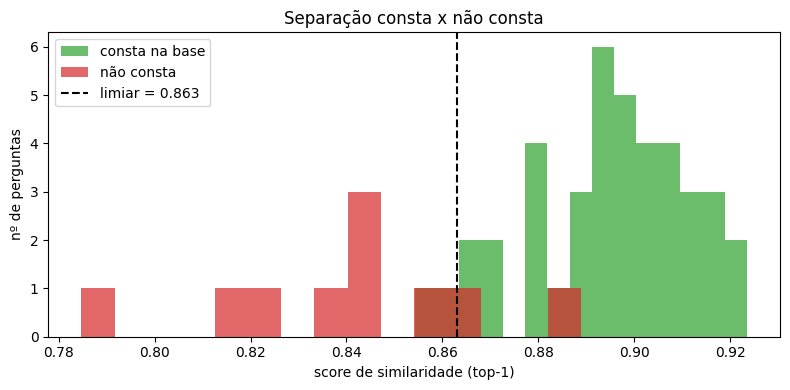

In [6]:
import matplotlib.pyplot as plt
res = escolher_limiar(casos, r)
print("limiar:", round(res["limiar"], 4), "| acurácia balanceada:", round(res["acuracia_balanceada"], 3))
plt.figure(figsize=(8, 4))
plt.hist(res["scores_consta"], bins=15, alpha=.7, label="consta na base", color="tab:green")
plt.hist(res["scores_nao_consta"], bins=15, alpha=.7, label="não consta", color="tab:red")
plt.axvline(res["limiar"], color="k", ls="--", label=f"limiar = {res['limiar']:.3f}")
plt.xlabel("score de similaridade (top-1)"); plt.ylabel("nº de perguntas"); plt.legend(); plt.title("Separação consta x não consta")
plt.tight_layout(); plt.savefig("avaliacao/limiar.png", dpi=150); plt.show()
json.dump({"limiar": res["limiar"], "acuracia_balanceada": res["acuracia_balanceada"]}, open("avaliacao/limiar.json", "w"), indent=2)

## Justificativa do limiar (edite com seus números)
O gráfico mostra a sobreposição entre as duas classes. Abaixo do limiar a resposta é 'não consta' **sem chamar o LLM**, o que reduz alucinação e custo; acima, o LLM responde só com os trechos recuperados. Um limiar mais alto recusa mais (mais segurança, menos cobertura); um mais baixo cobre mais, mas deixa passar perguntas fora da base. Foi escolhido o ponto que equilibra os dois erros (acurácia balanceada impressa acima).